<a href="https://colab.research.google.com/github/emiliano-ipa/CEIA-PLN-desafios/blob/main/Desafios/Desafio_3/Desafio_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Procesamiento de lenguaje natural
## Desafío 3 · Modelo de lenguaje con tokenización por caracteres
**Alumno:** Emiliano Iparraguirre

### Consigna
- Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
- Realizar el pre-procesamiento adecuado para tokenizar el corpus, estructurar el dataset y separar entre datos de entrenamiento y validación.
- Proponer arquitecturas de redes neuronales basadas en unidades recurrentes para implementar un modelo de lenguaje.
- Con el o los modelos que consideren adecuados, generar nuevas secuencias a partir de secuencias de contexto con las estrategias de greedy search y beam search determístico y estocástico. En este último caso observar el efecto de la temperatura en la generación de secuencias.


### Sugerencias
- Durante el entrenamiento, guiarse por el descenso de la perplejidad en los datos de validación para finalizar el entrenamiento. Para ello se provee un callback.
- Explorar utilizar SimpleRNN (celda de Elman), LSTM y GRU.
- rmsprop es el optimizador recomendado para la buena convergencia. No obstante se pueden explorar otros.


### Objetivo
Entrenar un modelo de lenguaje **a nivel de carácter** con redes recurrentes sobre la saga de
d'Artagnan de Alexandre Dumas, el mismo corpus del Desafío 2, y usarlo para generar texto nuevo
de a un carácter por vez.

A diferencia del modelo de la clase 4, que predice la próxima *palabra*, acá cada token es un
carácter. Eso tiene tres consecuencias:
- **Vocabulario muy chico** (decenas de símbolos, no miles de palabras). El modelo nunca encuentra
  una palabra fuera de vocabulario, pero tiene que aprender a deletrear.
- **Secuencias más largas.** Una oración de 15 palabras ocupa unos 80 caracteres, así que la
  ventana de contexto tiene que ser más grande para abarcar la misma cantidad de texto.
- **Sin embedding.** Los caracteres no tienen significado semántico propio, así que se representan
  con vectores *one-hot* en lugar de entrenar una capa de embedding.

### Plan de trabajo
1. **Corpus:** descarga de los seis libros y exploración del texto a nivel de carácter.
2. **Preprocesamiento:** limpieza adaptada a un modelo por caracteres, construcción del vocabulario y tokenización.
3. **Dataset:** elección del tamaño de contexto, separación entre entrenamiento y validación, y armado de las
   secuencias *many-to-many* (entrada desplazada un carácter respecto del target).
4. **Modelos:** comparación de SimpleRNN, LSTM y GRU con una capa como línea de base, y después
   variantes con más capas, dropout y más unidades. Se registra la perplejidad en validación de
   cada experimento, incluidos los que no funcionaron.
5. **Generación:** con el mejor modelo, greedy search, beam search determinístico y beam search
   estocástico con distintas temperaturas.
6. **Conclusiones.**

**Nota sobre la plantilla:** se parte de la plantilla de la cátedra en Keras. Se corrigieron tres
detalles que afectan el cálculo de la perplejidad y la generación: la partición de las secuencias de
validación, la alineación de índices en el callback y el uso del índice 0 como padding. Cada corrección
se señala en la celda donde se aplica.

### 1 · Librerías y configuración
Se fija una semilla para que los experimentos sean reproducibles y se verifica que haya GPU disponible.

Como las sesiones de Colab se pueden cortar a mitad del entrenamiento, el corpus descargado y los
modelos se guardan en **Google Drive**. Así, si la sesión se reinicia, no hay que volver a bajar los
libros ni se pierde el mejor modelo entrenado.

> **Nota para ejecutar el notebook sin Google Drive:** el montaje de Drive es opcional. Para ejecutar el
> notebook sin montarlo, alcanza con poner `USAR_DRIVE = False` en la celda siguiente. En ese caso, el
> corpus, los modelos y los resultados se guardan en la carpeta de la sesión de Colab (`./dumas_corpus`,
> `./modelos` y `./resultados.json`), y la descarga de los libros y de los modelos ya entrenados desde
> GitHub funciona igual. La única diferencia es que esos archivos se pierden al cerrar la sesión, y si
> se cortara en medio de un reentrenamiento, habría que volver a empezar.

In [2]:
import os
import re
import random
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

import tensorflow as tf
from tensorflow import keras

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

# Carpeta de trabajo persistente en Drive (corpus + modelos)
USAR_DRIVE = True # False: guarda todo en la sesión de Colab (no requiere montar Drive)
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/CEIA-PLN/Desafio_3"
else:
    OUT_DIR = "."

DATA_DIR = os.path.join(OUT_DIR, "dumas_corpus")
MODEL_DIR = os.path.join(OUT_DIR, "modelos")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
print("Directorio de trabajo:", OUT_DIR)

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Directorio de trabajo: /content/drive/MyDrive/CEIA-PLN/Desafio_3


### 2 · Corpus: la saga de d'Artagnan

Se reutiliza el corpus del Desafío 2: los seis libros de *The d'Artagnan Romances* de Alexandre Dumas,
en la traducción al inglés de Project Gutenberg (dominio público).

| # | Libro | Ebook Gutenberg |
|---|-------|-----------------|
| 1 | The Three Musketeers | 1257 |
| 2 | Twenty Years After | 1259 |
| 3 | The Vicomte de Bragelonne | 2609 |
| 4 | Ten Years Later | 2681 |
| 5 | Louise de la Vallière | 2710 |
| 6 | The Man in the Iron Mask | 2759 |

**Por qué este corpus para un modelo por caracteres:**
- **Volumen:** unos 6,8 millones de caracteres, mucho más que el libro de ejemplo de la plantilla.
  Un modelo por caracteres necesita mucho texto para aprender a deletrear y a puntuar.
- **Estilo homogéneo:** es un solo autor y un solo traductor, con un registro constante y mucho
  diálogo con su atribución (*"…", said Athos*). Son patrones que un modelo por caracteres puede
  aprender: comillas que se abren y se cierran, comas antes del verbo de diálogo, nombres propios
  que se repiten.
- **Continuidad con el Desafío 2:** se conoce bien el texto y la limpieza ya probada sirve como base.

Igual que en el Desafío 2, se quitan el encabezado y la licencia que Gutenberg agrega a cada libro.

In [4]:
LIBROS = {
    1257: "The Three Musketeers",
    1259: "Twenty Years After",
    2609: "The Vicomte de Bragelonne",
    2681: "Ten Years Later",
    2710: "Louise de la Valliere",
    2759: "The Man in the Iron Mask",
}


def rutas_mirror(ebook_id):
    """Ruta de carpetas que usan los mirrors de Gutenberg: 1257 -> 1/2/5/1257."""
    s = str(ebook_id)
    return "/".join(s[:-1]) + "/" + s


def descargar_libro(ebook_id):
    """Descarga un libro de Gutenberg (o lo lee de disco si ya existe).
    Prueba primero el sitio principal y después mirrors oficiales."""
    path = os.path.join(DATA_DIR, f"pg{ebook_id}.txt")
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            return f.read()

    ruta = rutas_mirror(ebook_id)
    urls = [
        f"https://www.gutenberg.org/cache/epub/{ebook_id}/pg{ebook_id}.txt",
        f"https://www.gutenberg.org/ebooks/{ebook_id}.txt.utf-8",
        f"https://aleph.gutenberg.org/{ruta}/{ebook_id}-0.txt",
        f"https://aleph.gutenberg.org/{ruta}/{ebook_id}.txt",
        f"https://mirror.csclub.uwaterloo.ca/gutenberg/{ruta}/{ebook_id}-0.txt",
        f"https://mirror.csclub.uwaterloo.ca/gutenberg/{ruta}/{ebook_id}.txt",
        f"https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_3/dumas_corpus/pg{ebook_id}.txt",
    ]
    headers = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) CEIA-PLN desafio 3"}
    for url in urls:
        try:
            r = requests.get(url, timeout=60, headers=headers)
            print(f"  {ebook_id} · {r.status_code} · {len(r.content):>9,} bytes · {url}")
            if r.status_code == 200 and len(r.content) > 100_000:
                r.encoding = "utf-8"
                with open(path, "w", encoding="utf-8") as f:
                    f.write(r.text)
                return r.text
        except requests.RequestException as e:
            print(f"  {ebook_id} · error · {url}: {e}")
    raise RuntimeError(f"No se pudo descargar el ebook {ebook_id}")


def extraer_cuerpo(texto):
    """Quita el encabezado y la licencia de Project Gutenberg."""
    inicio = re.search(r"\*\*\*\s*START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", texto, re.I)
    fin = re.search(r"\*\*\*\s*END OF (THE|THIS) PROJECT GUTENBERG EBOOK", texto, re.I)
    a = inicio.end() if inicio else 0
    b = fin.start() if fin else len(texto)
    return texto[a:b].strip()


registros = []
for ebook_id, nombre in LIBROS.items():
    registros.append({"ebook_id": ebook_id,
                      "libro": nombre,
                      "texto": extraer_cuerpo(descargar_libro(ebook_id))})

df_libros = pd.DataFrame(registros)
df_libros["caracteres"] = df_libros["texto"].str.len()
print(f"Total de caracteres en el corpus crudo: {df_libros['caracteres'].sum():,}")
df_libros[["ebook_id", "libro", "caracteres"]]

  1257 · 503 ·       913 bytes · https://www.gutenberg.org/cache/epub/1257/pg1257.txt
  1257 · 503 ·       913 bytes · https://www.gutenberg.org/ebooks/1257.txt.utf-8
  1257 · error · https://aleph.gutenberg.org/1/2/5/1257/1257-0.txt: HTTPSConnectionPool(host='aleph.gutenberg.org', port=443): Max retries exceeded with url: /1/2/5/1257/1257-0.txt (Caused by SSLError(SSLCertVerificationError(1, "[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'aleph.gutenberg.org'. (_ssl.c:1032)")))
  1257 · error · https://aleph.gutenberg.org/1/2/5/1257/1257.txt: HTTPSConnectionPool(host='aleph.gutenberg.org', port=443): Max retries exceeded with url: /1/2/5/1257/1257.txt (Caused by SSLError(SSLCertVerificationError(1, "[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'aleph.gutenberg.org'. (_ssl.c:1032)")))
  1257 · 200 · 1,337,947 bytes · https://mirror.csclub.uwaterloo.ca/gutenberg/1

,ebook_id,libro,caracteres
0,1257,The Three Musketeers,1297963
1,1259,Twenty Years After,1368566
2,2609,The Vicomte de Bragelonne,1078548
3,2681,Ten Years Later,1102508
4,2710,Louise de la Valliere,981438
5,2759,The Man in the Iron Mask,1016503


#### Control de la extracción

Como el sitio principal de Gutenberg devolvió error 503 desde Colab, los libros se descargaron de un mirror
oficial. Al comparar con el Desafío 2, tres libros (*Ten Years Later*, *Louise de la Vallière* y *The Man in
the Iron Mask*) tenían unos 22.000 caracteres más. Las dos celdas siguientes verifican de dónde viene esa
diferencia: si quedaron restos de la licencia de Gutenberg y qué texto aparece entre corchetes.

In [5]:
# Control: ¿quedaron restos del encabezado o la licencia de Gutenberg?
for _, row in df_libros.iterrows():
    t = row["texto"]
    print(f"{row['libro']:<28} menciones de 'gutenberg': {len(re.findall('gutenberg', t, re.I)):>3}")
    print("   final:", repr(t[-300:]))

The Three Musketeers         menciones de 'gutenberg':   0
   final: ' future. In fact, M. Bonacieux, having\nleft his house at seven o’clock in the evening to go to the Louvre,\nnever appeared again in the Rue des Fossoyeurs; the opinion of those\nwho seemed to be best informed was that he was fed and lodged in some\nroyal castle, at the expense of his generous Eminence.'
Twenty Years After           menciones de 'gutenberg':   2
   final: 'fair Madeleine, his hostess, standing on the threshold.\n\n“Madeleine,” said the Gascon, “give me your apartment on the first\nfloor; now that I am a captain in the royal musketeers I must make an\nappearance; nevertheless, reserve my old room on the fifth story for\nme; one never knows what may happen.”'
The Vicomte de Bragelonne    menciones de 'gutenberg':   1
   final: 'the cabinet, when an usher pushing\nby him, exclaimed: “A courier from Bretagne for his majesty.”\n\n“M. d’Herblay was right,” murmured Fouquet, pulling out his watch; “an\nhour

In [6]:
# Control: formato de las notas al pie y contexto de las menciones a Gutenberg
for _, row in df_libros.iterrows():
    t = row["texto"]
    notas_bloque = re.findall(r"\[Footnote[^\]]{0,40}", t)
    llamadas = Counter(re.findall(r"\[[^\]\n]{1,12}\]", t))
    print(f"\n{row['libro']}")
    print(f"   bloques '[Footnote ...': {len(notas_bloque)}")
    print(f"   marcas cortas entre corchetes (top 8): {llamadas.most_common(8)}")
    for m in re.finditer("gutenberg", t, re.I):
        print("   gutenberg →", repr(t[max(0, m.start() - 120): m.end() + 80]))


The Three Musketeers
   bloques '[Footnote ...': 0
   marcas cortas entre corchetes (top 8): []

Twenty Years After
   bloques '[Footnote ...': 0
   marcas cortas entre corchetes (top 8): [('[pettifogger]', 1), ('[minister]', 1)]
   gutenberg → 'Twenty Years After\n\nBy Alexandre Dumas, Père\n\nSecond Volume of the D’Artagnan Series\n\n\n\n\nLINKED INDEX OF PROJECT GUTENBERG VOLUMES:\n\nORDER   TITLE                       PG EBOOK#    DATES       VOLUME  '
   gutenberg → '661         3         141–208\n6       The Man in the Iron Mask    2759         1661–1673    3         209–269\n\n[Project Gutenberg eBook 1258 listed below, is of the same title as\neBook 2681 and its contents ov'

The Vicomte de Bragelonne
   bloques '[Footnote ...': 0
   marcas cortas entre corchetes (top 8): []
   gutenberg → 'counsels.\n Chapter LXXV. In which Monsieur Fouquet Acts.\n\n\n\n\nOriginal Transcriber’s Note:\n\nAs you may be aware, Project Gutenberg has been involved with the\nwritings of both the Al

**Resultado del control:**
- **La licencia quedó bien recortada:** ningún libro termina con texto legal.
- **La diferencia viene de otro lado:** los archivos del mirror son una edición anterior que trae las **notas
  al pie del traductor** juntas al final (`[Footnote N: …]`), entre 11 y 14 por libro, con sus llamadas `[N]`
  dentro del texto.
- **Material previo a la narración:** aparecen la tabla de volúmenes de Gutenberg (libro 2) y una nota del
  transcriptor (libros 3 a 6).
- **Glosas del traductor:** algunas palabras traducidas aparecen entre corchetes (`[minister]`, `[pettifogger]`).

Todo esto se elimina en el preprocesamiento.

### 3 · Exploración del texto crudo a nivel de carácter

En un modelo por caracteres, **cada símbolo distinto es una clase de salida de la red**. Por eso, antes
de limpiar, conviene ver:
- **Cuántos caracteres distintos hay y con qué frecuencia aparecen.** Un símbolo que aparece pocas
  veces (un `£`, una `ñ`) suma una clase que el modelo casi no puede aprender.
- **Cómo vienen los saltos de línea.** Gutenberg corta las líneas a unos 70 caracteres en mitad de
  la oración. Si se dejan, el modelo aprende a meter un `\n` cada 70 caracteres, un patrón que es de
  formato y no del lenguaje.
- **Qué variantes tipográficas existen** de un mismo signo (comillas rectas y tipográficas, guiones),
  que para el modelo serían caracteres distintos.

In [7]:
corpus_crudo = "\n".join(df_libros["texto"])
frec_crudo = Counter(corpus_crudo)

df_frec_crudo = (pd.DataFrame(frec_crudo.most_common(), columns=["caracter", "frecuencia"])
                   .assign(caracter=lambda d: d["caracter"].map(repr)))

print(f"Caracteres totales: {len(corpus_crudo):,}")
print(f"Caracteres distintos (crudo): {len(frec_crudo)}")
print(f"Caracteres distintos que aparecen menos de 100 veces: {(df_frec_crudo['frecuencia'] < 100).sum()}")
print(f"Saltos de línea: {frec_crudo['\n']:,}  "
      f"(uno cada {len(corpus_crudo) / frec_crudo['\n']:.0f} caracteres)")

# Los 25 menos frecuentes: candidatos a normalizar o eliminar
print("\nLos 25 caracteres menos frecuentes:")
print(df_frec_crudo.tail(25).to_string(index=False))

# Fragmento crudo del medio del primer libro, mostrando los saltos de línea
t = df_libros.loc[0, "texto"]
print("\nFragmento crudo (repr):")
print(repr(t[len(t) // 2: len(t) // 2 + 400]))

Caracteres totales: 6,845,531
Caracteres distintos (crudo): 103
Caracteres distintos que aparecen menos de 100 veces: 25
Saltos de línea: 161,615  (uno cada 42 caracteres)

Los 25 caracteres menos frecuentes:
caracter  frecuencia
     '['          93
     ']'          92
     '5'          91
     '8'          80
     '*'          62
     '7'          58
     '3'          55
     'ê'          49
     '9'          42
     'Z'          35
     'œ'          31
     'à'          16
     '–'          10
     'É'           7
     'æ'           7
     'ï'           7
     'î'           5
     'ç'           3
     '/'           3
     '#'           2
     '@'           2
     '£'           1
     'ñ'           1
     'Œ'           1
     '&'           1

Fragmento crudo (repr):
' apply to me.”\n\n“Fie, madame, fie!” said Porthos, as if disgusted. “Let us not talk\nabout money, if you please; it is humiliating.”\n\n“Then you no longer love me!” said the procurator’s wife, slowly and\nsadly.\n\nP

**Observaciones:**
- **Hay 103 caracteres distintos en el texto crudo,** más del doble de los 49 que quedan después de limpiar.
  Se suman las mayúsculas, las variantes tipográficas de un mismo signo (`“ ” "`, `’ '`, `— – -`), las
  letras con tilde de los nombres franceses y el `\r` de los saltos de línea de Windows de los libros 4 a 6.
- **25 caracteres aparecen menos de 100 veces.** Entre ellos están:
  - letras con tilde (`ê`, `à`, `É`, `ï`, `î`, `ç`), ligaduras (`œ`, `æ`) y símbolos sueltos (`£`, `#`, `@`, `/`, `&`),
    que suman clases que el modelo casi no puede aprender;
  - los **corchetes** (unas 90 apariciones), que anticipan las notas al pie y las glosas del traductor;
  - **varios dígitos** (`3`, `5`, `7`, `8`, `9`), mientras que el `1` y el `6` son frecuentes por los años 16xx. Esa
    diferencia es la que después obligó a exceptuar los dígitos del filtro de caracteres raros.
- **Hay un salto de línea cada 42 caracteres** (161.615 en total), casi cuatro por párrafo. En el fragmento se ve
  que cortan las oraciones a la mitad (*"Let us not talk\nabout money"*): son cortes de formato que el modelo no
  debe aprender. El salto que separa párrafos aparece doble (`\n\n`) y sí tiene sentido, porque separa turnos de diálogo.
- **El fragmento confirma los demás artefactos a limpiar:** comillas y apóstrofos tipográficos (`“ ” ’`) y las marcas
  de itálica de Gutenberg (`_here!_`).

### 4 · Preprocesamiento

La limpieza del Desafío 2 eliminaba la puntuación y las stopwords porque el objetivo eran los
embeddings de palabras. Acá es al revés: **la puntuación, los espacios y los saltos de línea son
parte de lo que el modelo tiene que aprender a generar**, así que se conservan, como recomendó la
profesora. La limpieza se limita a quitar el texto que no es de Dumas, los artefactos de formato
y las variantes de un mismo signo.

Al explorar los archivos aparecieron tres tipos de texto ajeno a la novela, que se eliminan:
- **Material previo a la narración:** índice, la tabla de volúmenes de Gutenberg (libro 2) y la
  *Transcriber's Note* de los libros 3 a 6.
- **Notas al pie del traductor** (`[Footnote N: …]`), juntas al final de los libros 4 a 6, con
  sus llamadas `[N]` dentro del texto.
- **Glosas entre corchetes** que agrega el traductor (`[pettifogger]`, `[minister]`).

| Decisión | Qué se hace | Por qué |
|---|---|---|
| **Inicio de la narración** | Cada libro empieza en el primer título de capítulo seguido de narración | Descarta de una vez el índice y las notas del transcriptor, que no son de Dumas y tienen otro estilo. |
| **Notas al pie y glosas** | Se descartan los párrafos `[Footnote …]` y se quitan los corchetes dentro del texto | Son agregados del traductor, con un formato que no aparece en la narración. |
| **Títulos de capítulo** | Se descartan los párrafos que empiezan con *Chapter* o están mayormente en mayúsculas | Son títulos, no narración. |
| **Saltos de línea** | Se unen las líneas de cada párrafo y los párrafos se separan con un único `\n` | Los cortes a 70 caracteres son de formato. El `\n` entre párrafos sí tiene sentido: separa turnos de diálogo. |
| **Comillas y apóstrofos** | `“ ”` → `"` y `’ ‘` → `'` | Son el mismo signo para el modelo. Unificarlos le ahorra clases y le facilita aprender que toda comilla que se abre se cierra. |
| **Guiones** | `—` y `–` → `-` | Mismo criterio: tres guiones distintos serían tres clases. |
| **Itálicas** | Se quitan las marcas `_` | Son marcas de formato de Gutenberg, no texto. |
| **Tildes** | Se transliteran (*Tréville* → *treville*, *cœur* → *coeur*) | Son pocas y se concentran en nombres propios. Con tan pocos ejemplos el modelo no aprendería a usarlas, y cada una sería una clase más. |
| **Minúsculas** | Todo el texto se pasa a minúsculas, como en la plantilla | Reduce el vocabulario casi a la mitad. Se pierde la mayúscula inicial de oración, pero el modelo igual tiene que aprender dónde termina una oración (punto + espacio). |
| **Caracteres raros** | Se eliminan los que aparecen menos de `MIN_FREC` veces después de normalizar, **excepto los dígitos** | Clases con tan pocos ejemplos solo agrandan la capa de salida. Los dígitos se exceptúan porque se usan juntos: si se borraran los menos frecuentes, *1625* quedaría como *16*. |

In [9]:
MIN_FREC = 50   # frecuencia mínima para que un carácter quede en el vocabulario

REEMPLAZOS = {
    "“": '"', "”": '"', "’": "'", "‘": "'",
    "—": "-", "–": "-",
    "œ": "oe", "Œ": "Oe", "æ": "ae", "Æ": "Ae",
    "_": "",
}


def normalizar(texto):
    """Unifica saltos de línea, comillas, guiones, itálicas y tildes."""
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    for a, b in REEMPLAZOS.items():
        texto = texto.replace(a, b)
    texto = unicodedata.normalize("NFKD", texto)                      # é -> e + tilde combinante
    texto = "".join(c for c in texto if not unicodedata.combining(c))  # quita la tilde
    return texto


def es_titulo_capitulo(p):
    return re.match(r"^chapter\b", p, re.I) is not None


def es_encabezado(parrafo):
    """True si el párrafo es un título de capítulo o un bloque mayormente en mayúsculas."""
    if es_titulo_capitulo(parrafo):
        return True
    letras = [c for c in parrafo if c.isalpha()]
    if not letras:
        return True
    # el umbral de 4 letras evita descartar diálogos cortos como "I." u "Oh!"
    return len(letras) >= 4 and sum(c.isupper() for c in letras) / len(letras) > 0.5


def inicio_narracion(parrafos):
    """Índice del primer título de capítulo suelto (corto) seguido de un párrafo que no es título.
    El índice del libro queda excluido porque es un único párrafo largo con todos los títulos."""
    for i in range(len(parrafos) - 1):
        p = parrafos[i]
        if es_titulo_capitulo(p) and len(p) < 150 and not es_titulo_capitulo(parrafos[i + 1]):
            return i
    return None


parrafos_limpios = []
descartes = Counter()
resumen = []

for _, row in df_libros.iterrows():
    parrafos = [" ".join(p.split()) for p in re.split(r"\n\s*\n", normalizar(row["texto"]))]
    parrafos = [p for p in parrafos if p]

    i0 = inicio_narracion(parrafos)
    if i0 is None:
        print(f"ATENCIÓN: no se encontró el inicio de la narración en {row['libro']}; se conserva todo.")
        i0 = 0
    previo = sum(len(p) for p in parrafos[:i0])

    n_antes = len(parrafos_limpios)
    for p in parrafos[i0:]:
        if re.match(r"^\[footnote", p, re.I):
            descartes["nota al pie"] += 1
            continue
        if re.match(r"^end of\b", p, re.I) and re.search(r"next text|series", p, re.I):
            descartes["nota editorial de cierre"] += 1
            continue
        if es_encabezado(p):
            descartes["título de capítulo / mayúsculas"] += 1
            continue
        p = re.sub(r"\s*\[[^\]]{1,60}\]", "", p).strip()   # llamadas [N] y glosas [minister]
        if p:
            parrafos_limpios.append(p)

    resumen.append({"libro": row["libro"],
                    "caract. previos descartados": previo,
                    "párrafos conservados": len(parrafos_limpios) - n_antes,
                    "comienza con": parrafos[i0 + 1][:70]})

display(pd.DataFrame(resumen))
print("Párrafos descartados dentro de la narración:", dict(descartes))

article_text = "\n".join(parrafos_limpios).lower()

# Eliminación de caracteres raros
frec = Counter(article_text)
raros = {c: n for c, n in frec.items() if n < MIN_FREC and not c.isdigit()}
if raros:
    article_text = "".join(c for c in article_text if c not in raros)

print(f"\nCaracteres raros eliminados (< {MIN_FREC} apariciones): {raros}")
print(f"Caracteres totales después de limpiar: {len(article_text):,} "
      f"({len(article_text) / len(corpus_crudo):.1%} del crudo)")
print(f"Corchetes que quedaron en el texto: {article_text.count('[')}")

chars_vocab = sorted(set(article_text))
print(f"\nTamaño del vocabulario: {len(chars_vocab)} caracteres")
print(chars_vocab)

print("\nFragmento limpio:")
print(article_text[len(article_text) // 2: len(article_text) // 2 + 600])

,libro,caract. previos descartados,párrafos conservados,comienza con
0,The Three Musketeers,7197,8093,"On the first Monday of the month of April, 162..."
1,Twenty Years After,4622,10001,"In a splendid chamber of the Palais Royal, for..."
2,The Vicomte de Bragelonne,11915,6466,"Towards the middle of the month of May, in the..."
3,Ten Years Later,10277,6470,The reader guesses beforehand whom the usher p...
4,Louise de la Valliere,13525,5871,During all these long and noisy debates betwee...
5,The Man in the Iron Mask,17865,5360,Since Aramis's singular transformation into a ...


Párrafos descartados dentro de la narración: {'título de capítulo / mayúsculas': 448, 'nota editorial de cierre': 4, 'nota al pie': 36}

Caracteres raros eliminados (< 50 apariciones): {'*': 31, '£': 1, '&': 1, '[': 4, ']': 5}
Caracteres totales después de limpiar: 6,638,726 (97.0% del crudo)
Corchetes que quedaron en el texto: 0

Tamaño del vocabulario: 49 caracteres
['\n', ' ', '!', '"', "'", '(', ')', ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '?', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

Fragmento limpio:
side, m. fouquet on the other,-more than a hundred millions perhaps between them! no wonder my coffers should be empty!" colbert waited without stirring.
"and is the sum you bring me worth the trouble?" asked the king.
"yes, sire, it is a round sum."
"amounting to how much?"
"to thirteen millions of livres, sire."
"thirteen millions!" cried louis, trembling wit

**Observaciones:**

- **Inicio de la narración:** la regla funcionó en los seis libros. Todos empiezan en el primer párrafo
  del capítulo I (*"On the first Monday of the month of April, 1625…"* en *The Three Musketeers*). Antes de ese punto
  se descartaron entre 4.600 y 17.900 caracteres por libro: el índice, el prefacio del autor en el libro 1,
  la tabla de volúmenes de Gutenberg en el libro 2 y la nota del transcriptor en los libros 3 a 6.
- **Dentro de la narración** se descartaron 448 títulos de capítulo, 36 notas al pie y 4 notas editoriales
  de cierre (*"End of The Vicomte de Bragelonne. The next text in the series is…"*). No quedó ningún corchete.
- **Volumen:** quedan unos **6,64 millones de caracteres**, el 97% del texto crudo. La limpieza saca poco
  porque casi todo el corpus es narración. Lo que se fue es formato y texto que no es de Dumas.
- **Vocabulario de 49 caracteres:** las 26 letras, los 10 dígitos, el espacio, el salto de línea y 11 signos
  de puntuación (`! " ' ( ) , - . : ; ?`). Es mucho más chico que los miles de palabras de un modelo por
  palabras, y la capa de salida pasa a ser una clasificación entre 49 clases.
- **Dígitos:** en una primera versión, el filtro de caracteres raros (< 50 apariciones) eliminó 8 de los 10
  dígitos. Conservaba solo el `1` y el `6`, frecuentes por los años 16xx, y eso rompía los números (*1625* → *16*).
  Por eso los dígitos se exceptuaron del filtro. Los únicos caracteres eliminados por raros fueron `* £ & [ ]`,
  con menos de 35 apariciones cada uno.
- **El fragmento limpio** muestra la estructura que el modelo tiene que aprender: un turno de diálogo por
  línea, comillas que abren y cierran, la atribución del diálogo (*cried louis*, *asked the king*) y
  vocativos con coma (*sire*, *monsieur colbert*).
- **Artefacto aceptado:** el guion largo pegado a una coma queda como `,-` (*"on the other,-more than…"*).
  Es poco frecuente y no justifica una regla adicional.

### 5 · Vocabulario y tokenización

El vocabulario es el conjunto de caracteres distintos del texto limpio. Cada carácter recibe un índice
entero y `char2idx` funciona como tokenizador.

**Corrección a la plantilla:** la plantilla asigna los índices desde 0, pero después usa `pad_sequences`,
que rellena con 0. Así, el relleno se confunde con un carácter real: el modelo vería, por ejemplo, una
seguidilla de letras *"e"* delante de cada texto corto. Acá **los índices empiezan en 1 y el 0 queda
reservado para el padding**, igual que hace el `Tokenizer` de Keras en la clase 4. Por eso `vocab_size`
es la cantidad de caracteres más uno.

In [10]:
chars_vocab = sorted(set(article_text))

# índice 0 reservado para padding (corrección a la plantilla)
char2idx = {c: i + 1 for i, c in enumerate(chars_vocab)}
idx2char = {i: c for c, i in char2idx.items()}
idx2char[0] = ""                       # el padding no se imprime al decodificar
vocab_size = len(chars_vocab) + 1      # caracteres + padding

tokenized_text = np.array([char2idx[ch] for ch in article_text], dtype=np.int32)

print(f"Caracteres en el vocabulario: {len(chars_vocab)} | vocab_size (con padding): {vocab_size}")
print(f"Largo del texto tokenizado: {len(tokenized_text):,}")
print("Ejemplo:", repr(article_text[:40]))
print("Tokens: ", tokenized_text[:40].tolist())

Caracteres en el vocabulario: 49 | vocab_size (con padding): 50
Largo del texto tokenizado: 6,638,726
Ejemplo: 'on the first monday of the month of apri'
Tokens:  [38, 37, 2, 43, 31, 28, 2, 29, 32, 41, 42, 43, 2, 36, 38, 37, 27, 24, 48, 2, 38, 29, 2, 43, 31, 28, 2, 36, 38, 37, 43, 31, 2, 38, 29, 2, 24, 39, 41, 32]


**Observaciones:**
- El vocabulario tiene **49 caracteres**, más el índice 0 reservado para el padding: `vocab_size = 50`.
  Esa es la dimensión de la entrada *one-hot* y de la capa de salida softmax.
- El texto tokenizado tiene **6.638.726 tokens**, uno por carácter. En el modelo por palabras de la clase 4,
  el mismo texto daría unos 1,2 millones de tokens, pero con un vocabulario de decenas de miles de palabras.
  La tokenización por caracteres cambia vocabulario chico por secuencias más largas.
- En el ejemplo se ve que el espacio (índice 2) es uno de los tokens más repetidos: el modelo
  también tiene que aprender dónde terminan las palabras.

### 6 · Elección del tamaño de contexto

En un modelo por caracteres todo el corpus puede tratarse como un único documento, así que el contexto
no está limitado por el largo de las oraciones, como pasaba en la clase 4. La elección es un compromiso:
- **Contexto más largo:** el modelo ve más texto hacia atrás (por ejemplo, quién está hablando), pero
  cada secuencia es más costosa de entrenar, y una celda recurrente difícilmente aprovecha dependencias
  de cientos de pasos.
- **Contexto más corto:** se entrena más rápido, pero el modelo puede "olvidar" que abrió una comilla o
  de qué personaje se trata.

Para decidir con datos se mira el largo de los párrafos (en este corpus, casi siempre un turno de diálogo
o un bloque de narración) y cuántos caracteres ocupa una palabra en promedio.

Largo de párrafo en caracteres:
count    42261.0
mean       156.0
std        263.0
min          4.0
25%         43.0
50%         87.0
75%        173.0
90%        326.0
max       9079.0

Caracteres por palabra (incluido el espacio): 5.7


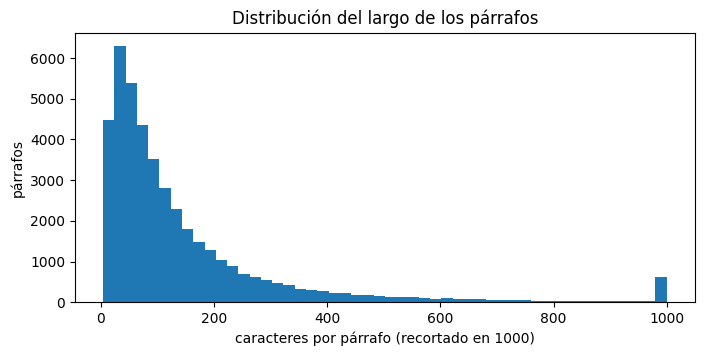

max_context_size = 100 caracteres (≈ 18 palabras)


In [11]:
largos_parrafo = pd.Series([len(p) for p in article_text.split("\n")])
n_palabras = len(article_text.split())

print("Largo de párrafo en caracteres:")
print(largos_parrafo.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(0).to_string())
print(f"\nCaracteres por palabra (incluido el espacio): {len(article_text) / n_palabras:.1f}")

plt.figure(figsize=(8, 3.5))
plt.hist(largos_parrafo.clip(upper=1000), bins=50)
plt.xlabel("caracteres por párrafo (recortado en 1000)")
plt.ylabel("párrafos")
plt.title("Distribución del largo de los párrafos")
plt.show()

max_context_size = 100
print(f"max_context_size = {max_context_size} caracteres "
      f"(≈ {max_context_size / (len(article_text) / n_palabras):.0f} palabras)")

**Observaciones y elección del contexto:**
- **Los párrafos son cortos y muy asimétricos:** la mediana es de **87 caracteres** y el 75% tiene menos
  de 173, pero la media sube a 156 y el máximo llega a 9.079 por una cola de bloques narrativos largos.
  En el histograma, la barra en 1.000 junta los párrafos de más de 1.000 caracteres (unos 600). La forma
  confirma lo que se veía en el texto: la mayoría de los párrafos son turnos de diálogo breves.
- **Equivalencia en palabras:** una palabra ocupa en promedio **5,7 caracteres** con su espacio, así que
  un contexto de 100 caracteres equivale a unas **17 o 18 palabras**, el largo de una oración típica.
- **Se eligió `max_context_size = 100`** por tres razones:
  1. **Cubre un párrafo típico:** alcanza para un párrafo completo en más de la mitad de los casos (la
     mediana es 87), así que el modelo puede ver, por ejemplo, la comilla que abrió el diálogo y el
     nombre de quien habla.
  2. **Rendimientos decrecientes:** un contexto más largo daría poca ganancia, porque una celda recurrente
     por caracteres difícilmente aprovecha dependencias de cientos de pasos.
  3. **Costo:** el costo de entrenamiento crece en proporción al largo de la secuencia, y hay que entrenar
     varias arquitecturas.

### 7 · Separación entre entrenamiento y validación, y estructura del dataset

**Separación:** como en la plantilla, se reserva el **último 10% del texto** para validación. Se corta
en un punto del texto y no se mezclan ventanas al azar, porque las ventanas de entrenamiento se solapan.
Si se separaran al azar, casi todos los caracteres de validación aparecerían también en alguna ventana de
entrenamiento. Ese 10% corresponde al final de *The Man in the Iron Mask*: es el mismo autor y el
mismo estilo, pero son capítulos que el modelo no vio.

**Secuencias de validación:** se parte el texto de validación en bloques consecutivos, sin solapamiento.
*Corrección a la plantilla:* la plantilla usa `val_text[init*L : init*(L+1)]`, que no genera bloques de
largo `L` sino de largo creciente (0, 1, 2, …), porque el fin del corte debería ser `(init+1)*L`. Acá cada
bloque tiene exactamente `L+1` caracteres: los primeros `L` son la entrada y los últimos `L`, desplazados
un lugar, son el target.

**Secuencias de entrenamiento (*many-to-many*):** igual que en la plantilla, la entrada es una ventana de
`L` caracteres [$x_0, …, x_{L-1}$] y el target es la misma ventana desplazada un lugar [$x_1, …, x_L$].
Así, la red recibe una señal de error en cada posición de la secuencia y no solo en la última.

**Paso entre ventanas (`PASO`):** la plantilla desliza la ventana de a un carácter. Con 6 millones de
caracteres eso daría unos 6 millones de secuencias por época, con cada carácter repetido en 100 ventanas
distintas. Es lo que llevó a 6 horas de entrenamiento en el ejemplo del año anterior y haría inviable
comparar varias arquitecturas en Colab. Con un paso de 10, cada carácter aparece en 10 ventanas, en
posiciones distintas y con distinto contexto previo. El dataset sigue cubriendo todo el texto, pero es
10 veces más chico. La ventana se arma con `sliding_window_view`, que no copia datos, en lugar de una
lista de Python.

In [12]:
from numpy.lib.stride_tricks import sliding_window_view

p_val = 0.1
PASO = 10

# --- separación en un punto del texto
corte = int(len(tokenized_text) * (1 - p_val))
train_text = tokenized_text[:corte]
val_text = tokenized_text[corte:]

# --- validación: bloques consecutivos de L+1 caracteres (corrección a la plantilla)
num_val = len(val_text) // (max_context_size + 1)
val_seqs = val_text[: num_val * (max_context_size + 1)].reshape(num_val, max_context_size + 1)
X_val, y_val = val_seqs[:, :-1], val_seqs[:, 1:]

# --- entrenamiento: ventanas de L+1 caracteres con paso PASO
ventanas = sliding_window_view(train_text, max_context_size + 1)[::PASO]
X = np.ascontiguousarray(ventanas[:, :-1])
y = np.ascontiguousarray(ventanas[:, 1:])

decode_txt = lambda seq: "".join(idx2char[int(i)] for i in seq)

print(f"Caracteres · entrenamiento: {len(train_text):,} | validación: {len(val_text):,}")
print(f"Entrenamiento · X: {X.shape}  y: {y.shape}  ({(X.nbytes + y.nbytes) / 1e6:.0f} MB)")
print(f"Validación    · X: {X_val.shape}  y: {y_val.shape}")
print("\nEjemplo de par entrada / target (primeros 60 caracteres):")
print("X:", repr(decode_txt(X[0, :60])))
print("y:", repr(decode_txt(y[0, :60])))

Caracteres · entrenamiento: 5,974,853 | validación: 663,873
Entrenamiento · X: (597476, 100)  y: (597476, 100)  (478 MB)
Validación    · X: (6573, 100)  y: (6573, 100)

Ejemplo de par entrada / target (primeros 60 caracteres):
X: 'on the first monday of the month of april, 1625, the market '
y: 'n the first monday of the month of april, 1625, the market t'


**Observaciones:**
- **Separación:** quedan **5,97 millones de caracteres de entrenamiento** y **664.000 de validación** (10%).
- **Entrenamiento:** con `PASO = 10` se generan **597.476 ventanas** de 100 caracteres, que ocupan 478 MB
  entre `X` e `y`. Con el paso de 1 de la plantilla serían unos 6 millones de ventanas y casi 5 GB, más de
  lo que conviene manejar en la RAM de Colab.
- **Validación:** el texto se parte en **6.573 bloques** sin solapamiento, lo que da 657.300 caracteres
  para evaluar la perplejidad en cada época.
- **El par de ejemplo** confirma la estructura *many-to-many*: `y` es `X` desplazado un carácter
  (*"on the first…"* → *"n the first…"*). En cada posición, el target es el carácter siguiente.

## 8 · Modelos

### Representación de la entrada
Como sugiere la plantilla, los caracteres se representan con vectores *one-hot* y **no se entrena
una capa de embedding**: un carácter suelto no tiene significado semántico que valga la pena aprender.

La plantilla arma el *one-hot* con `TimeDistributed(CategoryEncoding(...))`. Acá se usa una capa
`Embedding` con **pesos fijos en la matriz identidad** (`trainable=False`): cada índice se convierte
exactamente en su vector *one-hot*. El resultado es el mismo, pero esta capa acepta directamente
secuencias de índices de cualquier largo, se guarda y se carga sin problemas, y es más rápida.

### Arquitectura
Todos los modelos comparten la misma estructura, y lo que se varía en los experimentos es:
- **el tipo de celda recurrente:** SimpleRNN (Elman), LSTM o GRU;
- **la cantidad de capas recurrentes apiladas**, todas con `return_sequences=True` porque el
  problema es *many-to-many*;
- **el dropout** entre capas, con capas `Dropout` separadas y no con `recurrent_dropout`. Con
  `recurrent_dropout` la LSTM y la GRU no pueden usar la implementación optimizada de cuDNN en
  GPU, y el entrenamiento se vuelve varias veces más lento;
- **las unidades por capa.**

La salida es una capa densa softmax de `vocab_size` neuronas, aplicada en cada posición de la
secuencia. El optimizador es **RMSprop**, como recomienda la cátedra, con la función de pérdida
`sparse_categorical_crossentropy`, que recibe los índices de los targets sin pasarlos a *one-hot*.

In [13]:
import json
import time
from keras import layers

def crear_modelo(celda="LSTM", unidades=256, capas=1, dropout=0.0, lr=1e-3):
    Celda = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[celda]

    model = keras.Sequential()
    model.add(keras.Input(shape=(None,), dtype="int32"))
    # one-hot: embedding fijo con la matriz identidad (no se entrena)
    model.add(layers.Embedding(vocab_size, vocab_size,
                               embeddings_initializer="identity",
                               trainable=False, name="one_hot"))
    for _ in range(capas):
        model.add(Celda(unidades, return_sequences=True))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(vocab_size, activation="softmax"))

    model.compile(loss="sparse_categorical_crossentropy",
                  optimizer=keras.optimizers.RMSprop(learning_rate=lr))
    return model


crear_modelo("SimpleRNN", unidades=256).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ one_hot (Embedding)             │ (None, None, 50)       │         2,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, None, 256)      │        78,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 50)       │        12,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,942 (366.96 KB)

 Trainable params: 91,442 (357.20 KB)

 Non-trainable params: 2,500 (9.77 KB)

### Callback de perplejidad y early stopping

Se usa el callback de la plantilla, con la misma lógica: al final de cada época calcula la
perplejidad media en validación, **guarda el modelo cuando mejora** y **corta el entrenamiento
si no mejora durante `patience` épocas seguidas**. Tiene tres cambios:

1. **Una sola pasada por secuencia.** La plantilla arma, para cada secuencia de validación, todas sus
   subsecuencias con padding y predice sobre cada una: son 100 predicciones por secuencia, unas 657.000
   en total por época. Pero el modelo es recurrente y unidireccional, así que la salida en la posición
   *t* depende solo de los caracteres hasta *t*. Una sola pasada sobre la secuencia completa da la
   probabilidad del carácter siguiente en todas las posiciones a la vez. Es el mismo cálculo, unas 100
   veces más rápido. Es la alternativa "rápida" que habilitó la profesora.
2. **Corrección de índices.** En la plantilla, cada secuencia aporta `len_seq - 1` predicciones, pero
   el contador avanza `len_seq`. Así, desde la segunda secuencia las probabilidades quedan desalineadas
   de sus targets.
3. **Guardado en Drive y registro de la perplejidad de entrenamiento** (≈ `exp(loss)`). Comparar las dos
   curvas permite detectar sobreajuste.

La perplejidad de cada secuencia es $\exp\left(-\frac{1}{L}\sum_t \log p(x_{t+1} \mid x_{\le t})\right)$, y se
reporta el promedio sobre las secuencias, como en la plantilla.

**Puntos de referencia:** un modelo que eligiera al azar entre los 49 caracteres tendría una perplejidad de
**49**. Un modelo que solo conociera la frecuencia de cada carácter, sin mirar el contexto, tendría la
perplejidad unigrama que se calcula abajo. Cualquier red útil tiene que quedar bastante por debajo de ese valor.

In [14]:
class PplCallback(keras.callbacks.Callback):
    """Perplejidad en validación al final de cada época + guardado del mejor modelo + early stopping."""

    def __init__(self, X_val, y_val, ruta_modelo, patience=3):
        super().__init__()
        self.X_val, self.y_val = X_val, y_val
        self.ruta_modelo = ruta_modelo
        self.patience = patience
        self.history_ppl, self.history_ppl_train = [], []
        self.min_score, self.best_epoch, self.patience_counter = np.inf, 0, 0

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.X_val, batch_size=1024, verbose=0)          # (n, L, vocab)
        p_target = np.take_along_axis(probs, self.y_val[..., None], axis=-1)[..., 0]  # (n, L)
        ppl_seq = np.exp(-np.mean(np.log(p_target + 1e-10), axis=1))
        score = float(np.mean(ppl_seq))
        ppl_train = float(np.exp(logs["loss"]))

        self.history_ppl.append(score)
        self.history_ppl_train.append(ppl_train)
        print(f"   época {epoch + 1}: perplejidad train ≈ {ppl_train:.3f} | validación = {score:.3f}", end="")

        if score < self.min_score:
            self.min_score, self.best_epoch, self.patience_counter = score, epoch + 1, 0
            self.model.save(self.ruta_modelo)
            print("  → mejor modelo guardado")
        else:
            self.patience_counter += 1
            print(f"  (sin mejora {self.patience_counter}/{self.patience})")
            if self.patience_counter >= self.patience:
                print("   Early stopping")
                self.model.stop_training = True


# Referencia: perplejidad de un modelo unigrama (solo frecuencia de cada carácter, sin contexto)
frec_train = np.bincount(train_text, minlength=vocab_size).astype(float)
p_unigrama = frec_train / frec_train.sum()
ppl_unigrama = float(np.exp(-np.mean(np.log(p_unigrama[y_val.ravel()]))))
print(f"Perplejidad de referencia · azar uniforme: {len(chars_vocab)} | unigrama: {ppl_unigrama:.2f}")

Perplejidad de referencia · azar uniforme: 49 | unigrama: 20.14


**Observación:** la perplejidad de referencia del modelo unigrama es **20,14**: un modelo que solo
conoce la frecuencia de cada carácter "duda" en promedio entre unos 20 caracteres, contra 49 si
eligiera al azar. Es el piso que cualquier red tiene que superar holgadamente para demostrar que
aprendió algo del contexto. Si una red se queda cerca de 20, no está usando la secuencia.

### Entrenamiento y registro de experimentos

Una única función entrena cualquier configuración y guarda tres cosas en Drive:
- el mejor modelo (`.keras`);
- la perplejidad de cada época;
- un resumen del experimento: parámetros, mejor perplejidad, época en que se alcanzó y minutos de entrenamiento.

Así, si Colab corta la sesión, al volver a correr la celda los experimentos ya terminados se
**saltean** y no se pierde nada. Para repetir uno, se usa `reentrenar=True`.

**Hiperparámetros comunes a todos los experimentos:**
- **`BATCH = 512`:** con 597.000 ventanas son unos 1.170 pasos por época. Es el doble que en la plantilla,
  para aprovechar la GPU y acortar cada época.
- **`EPOCHS = 20` como máximo, con `PATIENCE = 3`:** a nivel de caracteres la perplejidad baja de forma
  suave. Si en 3 épocas seguidas no mejora, es poco probable que vuelva a bajar, y se ahorra tiempo
  para probar más arquitecturas.
- **RMSprop con `lr = 0.001`:** el valor por defecto, recomendado por la cátedra.

In [15]:
BATCH = 512
EPOCHS = 20
PATIENCE = 3

RES_PATH = os.path.join(OUT_DIR, "resultados.json")
resultados = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}


def entrenar(nombre, celda, unidades=256, capas=1, dropout=0.0, lr=1e-3,
             epochs=EPOCHS, batch_size=BATCH, patience=PATIENCE, reentrenar=False):
    ruta = os.path.join(MODEL_DIR, f"{nombre}.keras")
    if nombre in resultados and os.path.exists(ruta) and not reentrenar:
        print(f"{nombre}: ya entrenado (mejor perplejidad {resultados[nombre]['mejor_ppl']:.3f}), se omite.")
        return

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = crear_modelo(celda, unidades, capas, dropout, lr)
    cb = PplCallback(X_val, y_val, ruta, patience)

    print(f"\n{'=' * 70}\n{nombre} · {model.count_params():,} parámetros\n{'=' * 70}")
    t0 = time.time()
    model.fit(X, y, epochs=epochs, batch_size=batch_size, callbacks=[cb], verbose=2)
    minutos = (time.time() - t0) / 60

    resultados[nombre] = {
        "celda": celda, "capas": capas, "unidades": unidades, "dropout": dropout, "lr": lr,
        "parametros": model.count_params(),
        "mejor_ppl": cb.min_score, "mejor_epoca": cb.best_epoch,
        "epocas": len(cb.history_ppl), "minutos": round(minutos, 1),
        "hist_val": cb.history_ppl, "hist_train": cb.history_ppl_train,
    }
    with open(RES_PATH, "w") as f:
        json.dump(resultados, f)
    print(f"{nombre}: mejor perplejidad {cb.min_score:.3f} en la época {cb.best_epoch} · {minutos:.1f} min")


def tabla_resultados():
    cols = ["celda", "capas", "unidades", "dropout", "parametros",
            "mejor_ppl", "mejor_epoca", "epocas", "minutos"]
    return pd.DataFrame(resultados).T[cols].sort_values("mejor_ppl")


def graficar(nombres, titulo="Perplejidad por época"):
    plt.figure(figsize=(9, 4.5))
    for n in nombres:
        r = resultados[n]
        ep = range(1, len(r["hist_val"]) + 1)
        linea, = plt.plot(ep, r["hist_val"], marker="o", label=f"{n} · validación")
        plt.plot(ep, r["hist_train"], linestyle="--", color=linea.get_color(), alpha=0.6,
                 label=f"{n} · train")
    plt.xlabel("época")
    plt.ylabel("perplejidad")
    plt.title(titulo)
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.show()

### Modelos ya entrenados
Los modelos y los resultados de todos los experimentos están en el repositorio, en `Desafios/Desafio_3/`.
Esta celda los descarga a la carpeta de trabajo si todavía no están ahí. Así, las celdas de los
experimentos usan lo guardado en lugar de reentrenar, y el notebook corre completo en pocos minutos.
Para reentrenar todo desde cero, poner `DESCARGAR_DE_GITHUB = False`.

In [ ]:
DESCARGAR_DE_GITHUB = True
GITHUB_RAW = "https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_3"
MODELOS = ["SimpleRNN_1x256", "LSTM_1x256", "GRU_1x256",
           "GRU_2x256", "GRU_2x256_do02", "GRU_1x512"]

if DESCARGAR_DE_GITHUB:
    archivos = [("resultados.json", RES_PATH)] + \
               [(f"modelos/{m}.keras", os.path.join(MODEL_DIR, f"{m}.keras")) for m in MODELOS]
    for remoto, local in archivos:
        if os.path.exists(local):
            print(f"ya existe: {remoto}")
            continue
        r = requests.get(f"{GITHUB_RAW}/{remoto}", timeout=120)
        r.raise_for_status()
        with open(local, "wb") as f:
            f.write(r.content)
        print(f"descargado: {remoto} ({len(r.content) / 1e6:.1f} MB)")

    with open(RES_PATH) as f:                  # recarga el registro con los experimentos descargados
        resultados = json.load(f)
    print(f"\nExperimentos disponibles: {list(resultados)}")

> **⏱ Nota sobre los tiempos de ejecución**
>
> Los experimentos de las celdas siguientes entrenan 6 modelos más 10 épocas adicionales de la LSTM.
> En una GPU T4 de Colab llevan en total **unas 2 horas y 45 minutos**:
>
> | Experimento | Modelos | Tiempo aproximado |
> |---|---|---|
> | 1 · Comparación de celdas | SimpleRNN, LSTM y GRU (1 × 256) | 43 min |
> | 2 · LSTM con 10 épocas más | LSTM (1 × 256) | 9 min |
> | 3 · Variantes de la GRU | GRU 2 × 256, GRU 2 × 256 con dropout, GRU 1 × 512 | 1 h 51 min |
>
> Cada modelo y sus resultados se guardan en Google Drive apenas termina (`modelos/` y `resultados.json`).
> Si la carpeta ya contiene un experimento, la función `entrenar` **lo saltea** y usa lo guardado, así que
> volver a correr el notebook no repite el entrenamiento. Si la sesión de Colab se corta, alcanza con
> volver a correr todas las celdas: se retoma desde el primer experimento que no había terminado.
>
> Para correr el notebook desde cero, sin los modelos guardados, conviene verificar antes que el entorno
> tenga GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*). En CPU, el
> entrenamiento llevaría muchas horas.

> Los modelos ya entrenados están en el repositorio y la celda anterior los descarga automáticamente,
> así que **no hace falta reentrenar** para ejecutar el notebook completo ni para probar la generación.

### Experimento 1 · SimpleRNN vs. LSTM vs. GRU (línea de base)

Primero se comparan los tres tipos de celda en igualdad de condiciones: **una capa de 256 unidades,
sin dropout**, con el mismo dataset, optimizador y semilla. Así, la diferencia de perplejidad se puede
atribuir al tipo de celda.

Lo que se espera es que la SimpleRNN quede por detrás, porque sufre el desvanecimiento del gradiente
en secuencias de 100 pasos. La LSTM y la GRU, gracias a sus compuertas, deberían recordar mejor el
contexto, por ejemplo si hay una comilla abierta.


SimpleRNN_1x256 · 93,942 parámetros
Epoch 1/20
   época 1: perplejidad train ≈ 7.741 | validación = 5.903  → mejor modelo guardado
1167/1167 - 36s - 31ms/step - loss: 2.0465
Epoch 2/20
   época 2: perplejidad train ≈ 5.026 | validación = 4.774  → mejor modelo guardado
1167/1167 - 27s - 23ms/step - loss: 1.6147
Epoch 3/20
   época 3: perplejidad train ≈ 4.373 | validación = 4.410  → mejor modelo guardado
1167/1167 - 27s - 23ms/step - loss: 1.4754
Epoch 4/20
   época 4: perplejidad train ≈ 4.097 | validación = 4.219  → mejor modelo guardado
1167/1167 - 26s - 23ms/step - loss: 1.4103
Epoch 5/20
   época 5: perplejidad train ≈ 3.946 | validación = 4.104  → mejor modelo guardado
1167/1167 - 27s - 23ms/step - loss: 1.3726
Epoch 6/20
   época 6: perplejidad train ≈ 3.848 | validación = 4.034  → mejor modelo guardado
1167/1167 - 27s - 23ms/step - loss: 1.3475
Epoch 7/20
   época 7: perplejidad train ≈ 3.779 | validación = 3.983  → mejor modelo guardado
1167/1167 - 26s - 23ms/step - loss: 1.32

,celda,capas,unidades,dropout,parametros,mejor_ppl,mejor_epoca,epocas,minutos
GRU_1x256,GRU,1,256,0.0,251894,3.28616,20,20,16.0
LSTM_1x256,LSTM,1,256,0.0,329718,3.531105,20,20,18.4
SimpleRNN_1x256,SimpleRNN,1,256,0.0,93942,3.741177,20,20,9.0


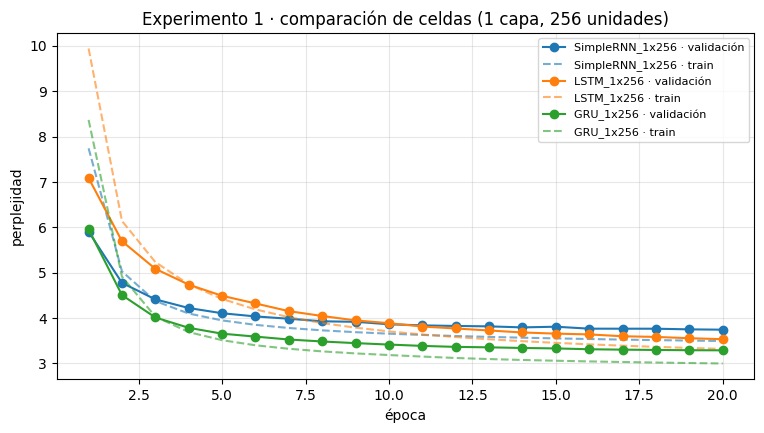

In [16]:
EXPERIMENTO_1 = [
    dict(nombre="SimpleRNN_1x256", celda="SimpleRNN"),
    dict(nombre="LSTM_1x256", celda="LSTM"),
    dict(nombre="GRU_1x256", celda="GRU"),
]

for cfg in EXPERIMENTO_1:
    entrenar(**cfg)

display(tabla_resultados())
graficar([cfg["nombre"] for cfg in EXPERIMENTO_1], "Experimento 1 · comparación de celdas (1 capa, 256 unidades)")

**Observaciones del experimento 1:**

| Celda | Parámetros | Perplejidad en validación | Seg./época | Minutos |
|---|---|---|---|---|
| GRU | 251.894 | **3,286** | 48 | 16,0 |
| LSTM | 329.718 | 3,531 | 55 | 18,4 |
| SimpleRNN | 93.942 | 3,741 | 27 | 9,0 |

- **Las tres celdas aprendieron la estructura del texto:** terminaron con una perplejidad de entre 3,3 y 3,7,
  muy por debajo del modelo unigrama (20,14) y del azar (49). En cada paso, el modelo "duda" en promedio
  entre poco más de 3 caracteres en lugar de 20: el contexto aporta muchísimo.
- **La GRU fue la mejor:** quedó un 12% por debajo de la SimpleRNN y un 7% por debajo de la LSTM. Además,
  convergió mucho más rápido: en la época 7 ya tenía la perplejidad que la LSTM alcanzó recién en la época 20.
- **La SimpleRNN aprende rápido al principio, pero se estanca:** en las tres primeras épocas supera a la LSTM,
  porque las dependencias cortas (deletrear una palabra, poner un espacio) no necesitan memoria larga. Desde la
  época 10 casi no mejora (de 3,86 a 3,74), y la LSTM la supera en la época 11. Es lo que se espera de una celda
  sin compuertas: el gradiente se desvanece a lo largo de los 100 pasos y no puede aprovechar el contexto lejano.
- **La LSTM arranca más lenta:** tiene más parámetros por unidad (cuatro compuertas contra tres de la GRU) y
  necesita más épocas para ajustarlos. En la primera época tuvo la peor perplejidad de las tres (7,09).
- **Ninguna llegó a converger:** las tres lograron su mejor valor en la época 20, el máximo permitido, y el early
  stopping nunca se activó. Pero el ritmo final es muy distinto. Entre las épocas 19 y 20, la GRU mejoró 0,002
  (está prácticamente estabilizada), la SimpleRNN 0,007 y la LSTM 0,022, todavía con una pendiente clara.
  Por eso, **la diferencia entre la LSTM y la GRU puede deberse en parte al límite de épocas** y no solo a la
  arquitectura. Esto se prueba en el experimento 2.
- **No hay sobreajuste:** la perplejidad de validación

### Experimento 2 · ¿La LSTM perdió por arquitectura o por épocas?

En el experimento 1, la LSTM seguía bajando con fuerza al llegar a la época 20. Para saber si con más
entrenamiento alcanzaría a la GRU, se **retoma el mejor modelo guardado y se entrena 10 épocas más**,
con el mismo early stopping. Como el archivo `.keras` guarda también el estado del optimizador, el
entrenamiento continúa exactamente donde quedó, sin empezar de cero.


LSTM_1x256 · continúa desde la época 20 (perplejidad 3.531)
Epoch 1/10
   época 1: perplejidad train ≈ 3.297 | validación = 3.519  → mejor modelo guardado
1167/1167 - 53s - 45ms/step - loss: 1.1931
Epoch 2/10
   época 2: perplejidad train ≈ 3.279 | validación = 3.505  → mejor modelo guardado
1167/1167 - 53s - 46ms/step - loss: 1.1876
Epoch 3/10
   época 3: perplejidad train ≈ 3.262 | validación = 3.493  → mejor modelo guardado
1167/1167 - 54s - 46ms/step - loss: 1.1825
Epoch 4/10
   época 4: perplejidad train ≈ 3.247 | validación = 3.482  → mejor modelo guardado
1167/1167 - 54s - 47ms/step - loss: 1.1776
Epoch 5/10
   época 5: perplejidad train ≈ 3.232 | validación = 3.467  → mejor modelo guardado
1167/1167 - 55s - 47ms/step - loss: 1.1731
Epoch 6/10
   época 6: perplejidad train ≈ 3.218 | validación = 3.462  → mejor modelo guardado
1167/1167 - 55s - 47ms/step - loss: 1.1689
Epoch 7/10
   época 7: perplejidad train ≈ 3.205 | validación = 3.448  → mejor modelo guardado
1167/1167 - 55s 

,celda,capas,unidades,dropout,parametros,mejor_ppl,mejor_epoca,epocas,minutos
GRU_1x256,GRU,1,256,0.0,251894,3.28616,20,20,16.0
LSTM_1x256,LSTM,1,256,0.0,329718,3.420245,30,30,27.5
SimpleRNN_1x256,SimpleRNN,1,256,0.0,93942,3.741177,20,20,9.0


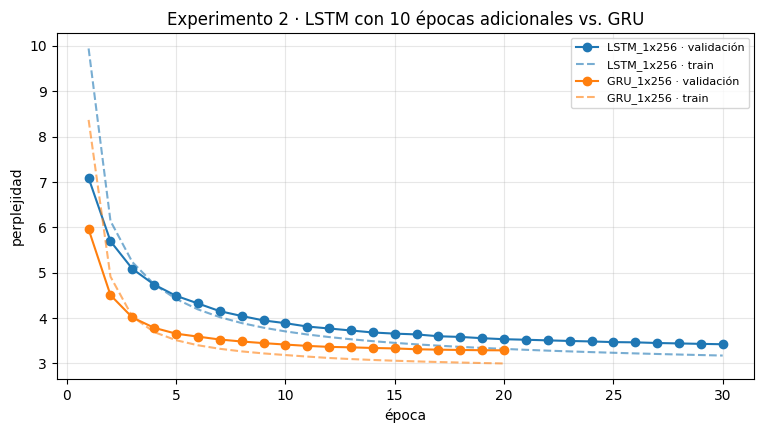

In [17]:
def continuar(nombre, epochs_extra=10, patience=PATIENCE, batch_size=BATCH):
    """Retoma el mejor modelo guardado de un experimento y lo entrena `epochs_extra` épocas más."""
    r = resultados[nombre]
    ruta = os.path.join(MODEL_DIR, f"{nombre}.keras")
    model = keras.models.load_model(ruta)

    cb = PplCallback(X_val, y_val, ruta, patience)
    cb.min_score = r["mejor_ppl"]          # solo se guarda si mejora lo ya logrado

    print(f"\n{'=' * 70}\n{nombre} · continúa desde la época {r['epocas']} "
          f"(perplejidad {r['mejor_ppl']:.3f})\n{'=' * 70}")
    t0 = time.time()
    model.fit(X, y, epochs=epochs_extra, batch_size=batch_size, callbacks=[cb], verbose=2)

    if cb.best_epoch:                       # hubo mejora en el tramo nuevo
        r["mejor_ppl"] = cb.min_score
        r["mejor_epoca"] = r["epocas"] + cb.best_epoch
    r["epocas"] += len(cb.history_ppl)
    r["minutos"] = round(r["minutos"] + (time.time() - t0) / 60, 1)
    r["hist_val"] += cb.history_ppl
    r["hist_train"] += cb.history_ppl_train
    with open(RES_PATH, "w") as f:
        json.dump(resultados, f)
    print(f"{nombre}: mejor perplejidad {r['mejor_ppl']:.3f} en la época {r['mejor_epoca']}")


if resultados["LSTM_1x256"]["epocas"] <= 20:     # evita repetirlo si se vuelve a correr la celda
    continuar("LSTM_1x256", epochs_extra=10)

display(tabla_resultados())
graficar(["LSTM_1x256", "GRU_1x256"], "Experimento 2 · LSTM con 10 épocas adicionales vs. GRU")

**Observaciones del experimento 2:**
- **Con 10 épocas más, la LSTM mejoró de 3,531 a 3,420, pero no alcanzó a la GRU (3,286).** Después de 30
  épocas quedó en un nivel que la GRU ya había alcanzado en la época 10 (3,413). Para ese resultado, la LSTM
  necesitó el triple de épocas y 27,5 minutos, contra unos 8 de la GRU.
- **La mejora se va frenando:** bajó 0,012 en la primera época adicional y 0,008 en la última. A ese ritmo
  decreciente, igualar a la GRU requeriría bastante más que otras 10 épocas, si es que llega.
- **Sigue sin sobreajustar:** la perplejidad de validación mejoró en las 10 épocas, y la distancia con la de
  entrenamiento (3,17 contra 3,42, un 8%) creció apenas.
- **Conclusión:** en el experimento 1, el límite de 20 épocas perjudicaba a la LSTM, pero no explica toda la
  diferencia. En este corpus, **la GRU aprende más rápido y llega más lejos**, con menos parámetros y menos
  tiempo. Una explicación posible es que la GRU tiene menos compuertas que ajustar y combina la memoria y el
  estado oculto en un solo vector, lo que facilita la optimización con una cantidad moderada de datos. Por
  eso, los experimentos de capacidad se hacen sobre la GRU.

### Experimento 3 · Más capacidad: profundidad, dropout y ancho

La GRU fue la mejor celda y ya estaba casi estabilizada en la época 20, así que mejorarla requiere **más
capacidad** y no más épocas. Se prueban tres variantes, cambiando una cosa por vez respecto de la GRU de
una capa:

| Experimento | Cambio | Pregunta |
|---|---|---|
| `GRU_2x256` | Dos capas apiladas | ¿Ayuda la profundidad? La segunda capa recibe las salidas de la primera y puede combinar patrones de más alto nivel (palabras, estructura del diálogo). |
| `GRU_2x256_do02` | Dos capas + dropout 0,2 | Con más parámetros aumenta el riesgo de sobreajuste. ¿El dropout mejora la validación o solo frena el aprendizaje en 20 épocas? |
| `GRU_1x512` | Una capa de 512 unidades | ¿Rinde más agrandar la capa que apilar otra? Tiene una cantidad de parámetros parecida a la de dos capas de 256. |

Se mantienen las 20 épocas máximas para que la comparación con el experimento 1 sea justa.


GRU_2x256 · 646,646 parámetros
Epoch 1/20
   época 1: perplejidad train ≈ 7.418 | validación = 4.990  → mejor modelo guardado
1167/1167 - 102s - 87ms/step - loss: 2.0039
Epoch 2/20
   época 2: perplejidad train ≈ 4.187 | validación = 3.988  → mejor modelo guardado
1167/1167 - 106s - 91ms/step - loss: 1.4319
Epoch 3/20
   época 3: perplejidad train ≈ 3.618 | validación = 3.684  → mejor modelo guardado
1167/1167 - 107s - 92ms/step - loss: 1.2860
Epoch 4/20
   época 4: perplejidad train ≈ 3.381 | validación = 3.522  → mejor modelo guardado
1167/1167 - 107s - 92ms/step - loss: 1.2182
Epoch 5/20
   época 5: perplejidad train ≈ 3.243 | validación = 3.414  → mejor modelo guardado
1167/1167 - 108s - 93ms/step - loss: 1.1764
Epoch 6/20
   época 6: perplejidad train ≈ 3.150 | validación = 3.358  → mejor modelo guardado
1167/1167 - 107s - 92ms/step - loss: 1.1475
Epoch 7/20
   época 7: perplejidad train ≈ 3.082 | validación = 3.315  → mejor modelo guardado
1167/1167 - 107s - 92ms/step - loss: 1.

,celda,capas,unidades,dropout,parametros,mejor_ppl,mejor_epoca,epocas,minutos
GRU_2x256,GRU,2,256,0.0,646646,3.184039,19,20,35.7
GRU_1x512,GRU,1,512,0.0,894454,3.188543,13,16,35.9
GRU_2x256_do02,GRU,2,256,0.2,646646,3.280178,20,20,39.1
GRU_1x256,GRU,1,256,0.0,251894,3.28616,20,20,16.0
LSTM_1x256,LSTM,1,256,0.0,329718,3.420245,30,30,27.5
SimpleRNN_1x256,SimpleRNN,1,256,0.0,93942,3.741177,20,20,9.0


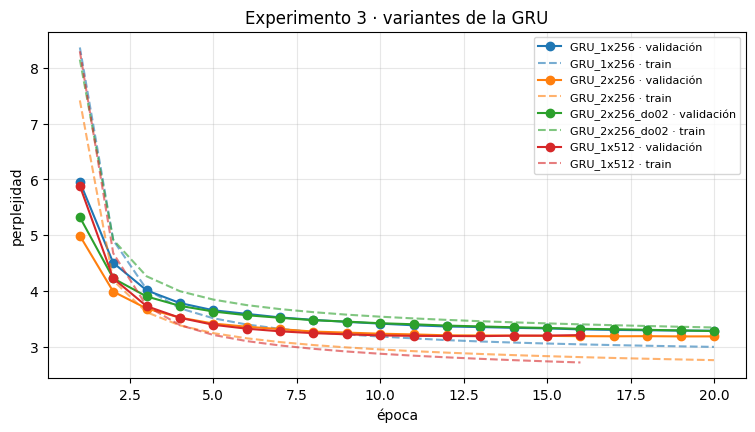

In [18]:
EXPERIMENTO_3 = [
    dict(nombre="GRU_2x256", celda="GRU", capas=2),
    dict(nombre="GRU_2x256_do02", celda="GRU", capas=2, dropout=0.2),
    dict(nombre="GRU_1x512", celda="GRU", unidades=512),
]

for cfg in EXPERIMENTO_3:
    entrenar(**cfg)

display(tabla_resultados())
graficar(["GRU_1x256"] + [cfg["nombre"] for cfg in EXPERIMENTO_3],
         "Experimento 3 · variantes de la GRU")

**Observaciones del experimento 3:**

| Modelo | Parámetros | Mejor perplejidad | Época | Minutos | Train al final |
|---|---|---|---|---|---|
| GRU_2x256 | 646.646 | **3,184** | 19 | 35,7 | 2,76 |
| GRU_1x512 | 894.454 | 3,189 | 13 (early stopping en la 16) | 35,9 | 2,72 |
| GRU_2x256_do02 | 646.646 | 3,280 | 20 | 39,1 | 3,34 |
| GRU_1x256 (base) | 251.894 | 3,286 | 20 | 16,0 | 3,00 |

- **Más capacidad mejora, pero poco:** las dos variantes sin dropout bajan la perplejidad de 3,29 a unos 3,19,
  apenas un 3%, con 2,6 a 3,6 veces más parámetros y más del doble de tiempo. Los rendimientos son claramente
  decrecientes. Con 6 millones de caracteres y un contexto de 100, la red ya captura casi todo lo que puede
  predecir el próximo carácter, y el margen que queda es chico.
- **Profundidad y ancho rinden casi igual** (3,184 contra 3,189), pero la red de dos capas lo logra con un 28% menos
  de parámetros. Apilar capas aprovecha mejor los parámetros que agrandar una sola.
- **Apareció el sobreajuste:**
  - **GRU_1x512:** su mejor valor fue en la época 13. Después, la perplejidad de validación **subió** tres
    épocas seguidas (3,197 → 3,208) mientras la de entrenamiento seguía bajando, y el early stopping cortó en
    la época 16, por primera vez en todos los experimentos.
  - **GRU_2x256:** muestra lo mismo, más atenuado. Desde la época 13 la validación casi no se mueve (3,201 →
    3,184), y la de entrenamiento sigue cayendo hasta 2,76: la distancia entre las dos curvas llega al 15%.
- **El dropout hizo exactamente lo esperado, pero en 20 épocas no alcanza:** con dropout 0,2, la red de dos capas
  no sobreajusta. Su perplejidad de entrenamiento queda incluso **por encima** de la de validación durante todo
  el entrenamiento, porque el dropout solo se aplica al entrenar. Pero frena el aprendizaje: en la época 20
  llega a 3,280, prácticamente igual que la GRU de una capa, y todavía baja unas 0,01 por época. Es la única
  variante que conserva margen de mejora con más épocas, a cambio de un entrenamiento bastante más largo.

**Modelo elegido para la generación: `GRU_2x256`.** Tiene la menor perplejidad en validación (3,184), con menos
parámetros que la GRU de 512 unidades y un sobreajuste más moderado. El archivo guardado corresponde a la época 19,
la de mejor validación, así que no arrastra las épocas en que empezó a sobreajustar.

### Resumen de los experimentos de arquitectura

,celda,capas,unidades,dropout,parametros,mejor_ppl,mejor_epoca,epocas,minutos
GRU_2x256,GRU,2,256,0.0,646646,3.184039,19,20,35.7
GRU_1x512,GRU,1,512,0.0,894454,3.188543,13,16,35.9
GRU_2x256_do02,GRU,2,256,0.2,646646,3.280178,20,20,39.1
GRU_1x256,GRU,1,256,0.0,251894,3.28616,20,20,16.0
LSTM_1x256,LSTM,1,256,0.0,329718,3.420245,30,30,27.5
SimpleRNN_1x256,SimpleRNN,1,256,0.0,93942,3.741177,20,20,9.0


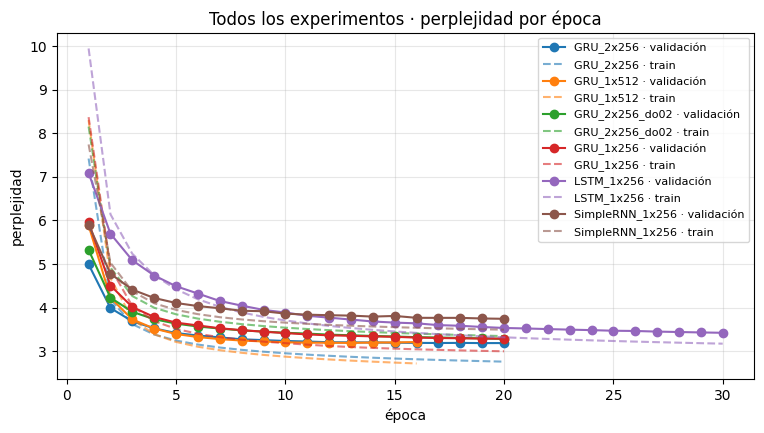

In [19]:
display(tabla_resultados())
graficar(list(tabla_resultados().index), "Todos los experimentos · perplejidad por época")

## 9 · Generación de secuencias

Se carga el mejor modelo guardado y se generan textos de 200 caracteres a partir de distintas frases
iniciales (*semillas*) escritas en el estilo de la novela. Se comparan las tres estrategias de la consigna:
greedy search, beam search determinístico y beam search estocástico con temperatura.

**Cambios respecto de las funciones de la plantilla:**
- **Sin padding de la semilla.** El modelo acepta secuencias de cualquier largo y en el entrenamiento nunca
  vio el padding: todas las ventanas eran texto real. Rellenar la semilla con ceros le mostraría un símbolo
  desconocido. Por eso se le pasa la semilla tal cual, recortada a los últimos `max_context_size`
  caracteres, igual que una ventana de entrenamiento que empieza en cualquier punto del texto.
- **Todos los haces del beam search se predicen en una sola llamada** al modelo, en lugar de una por haz.
  El resultado es el mismo, pero bastante más rápido.
- **En el modo estocástico, los candidatos se muestrean sin reposición**, para que no queden dos haces
  idénticos ocupando lugares del beam. La plantilla permite repetidos.

La lógica de selección de candidatos es la de la plantilla. En cada paso, cada haz se extiende con todos
los caracteres posibles, y el puntaje de cada candidato es la **suma de log-probabilidades** de toda la
secuencia. En el modo determinístico se quedan los `num_beams` mejores. En el estocástico se sortean con
probabilidad $\text{softmax}(\text{puntaje}/T)$, donde $T$ es la temperatura.

In [20]:
from scipy.special import softmax

MODELO_FINAL = "GRU_2x256"
model = keras.models.load_model(os.path.join(MODEL_DIR, f"{MODELO_FINAL}.keras"))
print(f"Modelo cargado: {MODELO_FINAL} · perplejidad en validación {resultados[MODELO_FINAL]['mejor_ppl']:.3f}")


def encode(text):
    text = text.lower()
    fuera = sorted(set(c for c in text if c not in char2idx))
    if fuera:
        print(f"  (caracteres fuera del vocabulario, se omiten: {fuera})")
    return np.array([char2idx[c] for c in text if c in char2idx], dtype=np.int32)


def decode(seq):
    return "".join(idx2char[int(i)] for i in seq)


def predecir_siguiente(model, seqs):
    """Distribución del próximo carácter para un lote de secuencias de igual largo."""
    x = np.asarray(seqs)[:, -max_context_size:]
    probs = model(x, training=False).numpy()[:, -1, :].astype(np.float64)
    probs[:, 0] = 0.0                                   # el padding nunca es una salida válida
    return probs / probs.sum(axis=1, keepdims=True)


def generate_seq(model, seed_text, n_chars=200):
    """Greedy search: en cada paso se agrega el carácter más probable."""
    seq = encode(seed_text)
    for _ in range(n_chars):
        p = predecir_siguiente(model, seq[None, :])[0]
        seq = np.append(seq, p.argmax())
    return decode(seq)


def beam_search(model, seed_text, num_beams=5, n_chars=200, mode="det", temp=1.0, seed=SEED):
    """Beam search determinístico (mode='det') o estocástico con temperatura (mode='sto')."""
    rng = np.random.default_rng(seed)
    beams = encode(seed_text)[None, :]
    scores = np.zeros(1)
    for _ in range(n_chars):
        p = predecir_siguiente(model, beams)                        # (haces, vocab)
        cand = (scores[:, None] + np.log(p + 1e-10)).ravel()        # log-prob acumulada de cada candidato
        if mode == "det":
            idx = np.argsort(cand)[::-1][:num_beams]
        elif mode == "sto":
            idx = rng.choice(cand.size, size=num_beams, replace=False, p=softmax(cand / temp))
        else:
            raise ValueError(f"Modo incorrecto: {mode}. Usar 'det' o 'sto'.")
        haz, caracter = np.divmod(idx, vocab_size)
        beams = np.concatenate([beams[haz], caracter[:, None]], axis=1)
        scores = cand[idx]
    orden = np.argsort(scores)[::-1]
    return [decode(b) for b in beams[orden]], scores[orden]


def mostrar_beam(salidas, scores, top=3):
    for i in range(min(top, len(salidas))):
        print(f"[{i + 1}] log-prob {scores[i]:.1f}\n{salidas[i]}\n")


SEMILLAS = [
    '"my dear d\'artagnan," said ',
    "the cardinal looked at ",
    "porthos drew his sword and ",
]

Modelo cargado: GRU_2x256 · perplejidad en validación 3.184


### Greedy search
En cada paso se elige el carácter más probable. Es determinístico: la misma semilla siempre da el mismo texto.

In [21]:
for s in SEMILLAS:
    print(generate_seq(model, s, n_chars=200), "\n")

"my dear d'artagnan," said the king, "i have not seen him a little and the same time the cardinal was still to say that the king had accompanied the cardinal and planchet and the street was still more surprised to his friends t 

the cardinal looked at him with a smile of the staircase, and the street was still more surprised to his friends the street the stairs, and the street was still more surprised to his friends the street the staircase had bee 

porthos drew his sword and the street was still more surprised to his friends the street the stairs, and the street was still more surprised to his friends the street the staircase had been the street the staircase he had recei 



**Observaciones del greedy search:**
- **El modelo aprendió a escribir en inglés carácter por carácter:** todas las palabras generadas existen,
  están bien deletreadas y separadas por espacios, y la puntuación aparece en lugares razonables. En la
  primera semilla, el modelo cierra la comilla del diálogo, pone la coma y la atribución (*said the king*) y
  abre un nuevo parlamento, que es la estructura típica de la novela.
- **Usa el vocabulario y los personajes del corpus** (*the king*, *the cardinal*, *planchet*), aunque las oraciones
  no tienen sentido global.
- **Cae rápido en un bucle:** las tres semillas terminan repitiendo la misma frase (*"and the street was still more
  surprised to his friends the street the stairs…"*). La segunda y la tercera semilla convergen casi al mismo
  texto, sin importar cómo empezaron. Es el problema característico de greedy: al elegir siempre el carácter más
  probable, el modelo entra en un ciclo de alta probabilidad y no puede salir, porque es determinístico y el
  contexto que se repite vuelve a producir las mismas predicciones.

### Beam search determinístico
Se mantienen los `num_beams` candidatos con mayor probabilidad acumulada. A diferencia de greedy, puede
elegir un carácter que no es el más probable en ese paso si la secuencia completa resulta más probable.
Se muestran los tres mejores haces finales.

In [22]:
for s in SEMILLAS:
    print("=" * 80, f"\nSemilla: {s!r} · beam determinístico (5 haces)\n")
    mostrar_beam(*beam_search(model, s, num_beams=5, n_chars=200, mode="det"))

Semilla: '"my dear d\'artagnan," said ' · beam determinístico (5 haces)

[1] log-prob -85.0
"my dear d'artagnan," said d'artagnan to himself, "there is nothing to say that your majesty will not have the honor of the king of france that your majesty will not have the honor of the king of france that your majesty has no

[2] log-prob -85.5
"my dear d'artagnan," said d'artagnan to himself, "there is nothing to say that your majesty will not have the honor of the king of france that your majesty will not have the honor of the king of france that your majesty wishes

[3] log-prob -85.6
"my dear d'artagnan," said d'artagnan to himself, "there is nothing to say that your majesty will not have the honor of the king of france that your majesty will not have the honor of the king of france that your majesty will b

Semilla: 'the cardinal looked at ' · beam determinístico (5 haces)

[1] log-prob -90.5
the cardinal looked at him with his hand to his friend's apartments, which had been passing thro

**Observaciones del beam search determinístico:**
- **Las frases son de mejor calidad que con greedy:** por ejemplo, *"porthos drew his sword and his friends were about
  to say that the king had accompanied the cardinal and planchet, who had not been sufficiently distinguished…"* es
  una oración larga, gramaticalmente plausible y con el registro de Dumas. Aparecen expresiones propias del corpus,
  como *your majesty*, *the king of france* o *hotel de ville*.
- **Respeta la estructura del diálogo:** después de *said* elige *d'artagnan to himself,* y abre correctamente una cita.
- **Sigue repitiendo:** *"that your majesty will not have the honor of the king of france"* aparece dos veces y *"which
  had been passing through the carriage"*, tres. Beam search maximiza la probabilidad de toda la secuencia, y en un
  modelo de lenguaje las secuencias más probables son justamente las repetitivas: el patrón ya apareció en el
  contexto y el modelo lo considera "seguro".
- **Los haces casi no se diferencian:** los tres mejores de cada semilla comparten casi todo el texto y difieren
  solo en los últimos caracteres. Con búsqueda determinística, los 5 haces terminan siendo variantes mínimas de
  un mismo camino.
- **El texto generado es "demasiado probable":** la log-probabilidad de 200 caracteres ronda −85 a −92, es
  decir, unos −0,44 nats por carácter. Equivale a una perplejidad de alrededor de **1,55**, muy por debajo de la
  perplejidad del modelo sobre texto real (3,18). El texto real es bastante más "sorprendente" que lo que produce
  el beam search: la búsqueda que maximiza la probabilidad genera un texto más plano y repetitivo que el escrito
  por una persona.

### Beam search estocástico: efecto de la temperatura
Los candidatos se sortean en proporción a $\text{softmax}(\text{puntaje}/T)$:
- **$T < 1$:** acentúa las diferencias entre candidatos y se acerca al beam determinístico.
- **$T = 1$:** sortea según las probabilidades del modelo.
- **$T > 1$:** aplana la distribución y le da más chances a los caracteres improbables.

Se usa la misma semilla y la misma semilla aleatoria en todos los casos, así que lo único que cambia es $T$.

In [23]:
semilla = SEMILLAS[0]
mostrar_beam(*beam_search(model, semilla, num_beams=5, mode="sto", temp=0.25), top=1)
mostrar_beam(*beam_search(model, semilla, num_beams=5, mode="sto", temp=0.5), top=1)
mostrar_beam(*beam_search(model, semilla, num_beams=5, mode="sto", temp=1.0), top=1)
mostrar_beam(*beam_search(model, semilla, num_beams=5, mode="sto", temp=1.5), top=1)
mostrar_beam(*beam_search(model, semilla, num_beams=5, mode="sto", temp=2.0), top=1)

[1] log-prob -88.5
"my dear d'artagnan," said the king, "there is nothing to say that your majesty will not have the honor of being seen that it is not the honor of the cardinal."
"what do you mean by that?" said d'artagnan, "you are right," said

[1] log-prob -74.9
"my dear d'artagnan," said the cardinal, looking at the comte de la fere himself, "there is nothing to say to your majesty."
"what do you mean by that?" said d'artagnan, "you are right, my dear friend," said d'artagnan, "i have

[1] log-prob -112.8
"my dear d'artagnan," said aramis, "it is not the means of the king of the slightest confidence in the hands of the street of m. de bragelonne's hands, which he had not been afraid that he had arrived at the door of the victim 

[1] log-prob -139.0
"my dear d'artagnan," said he, "that the king should come to him. he whom you have passed the flower of his serious than the most pressing of their friendship as the sight of the household of the cardinal himself, like a man wh

[1] lo

**Observaciones del beam search estocástico:**

| T | Log-prob | Qué se observa |
|---|---|---|
| 0,25 | −88,5 | Muy parecido al beam determinístico al principio (*"there is nothing to say that your majesty will not have the honor…"*), pero el sorteo le permite salir del bucle: cierra la cita y arranca un nuevo turno de diálogo. |
| **0,5** | **−74,9** | **El mejor texto:** un diálogo completo y coherente en lo local, con un personaje correcto (*the comte de la fere*, el título de Athos), una cita cerrada, un salto de párrafo y un nuevo intercambio (*"what do you mean by that?" said d'artagnan*). |
| 1,0 | −112,8 | Vocabulario más variado (*aramis*, *m. de bragelonne's*), pero la gramática se degrada (*"the slightest confidence in the hands of the street"*). |
| 1,5 | −139,0 | Construcciones cada vez más extrañas (*"the flower of his serious than the most pressing of their friendship"*). Las palabras siguen siendo reales. |
| 2,0 | −147,4 | Aparecen palabras inventadas (*mising*) y la sintaxis se rompe (*"bowing on the door, the blood turned his friend's apartments"*). |

- **La temperatura regula el equilibrio entre coherencia y diversidad.** Con T baja, el sorteo se concentra en
  los candidatos más probables y el texto se parece al determinístico. Con T alta, la distribución se aplana y
  ganan chances los caracteres improbables. Primero se pierde la gramática (T = 1 a 1,5) y después la ortografía
  (T = 2). En un modelo por caracteres, este último efecto es especialmente visible: un solo carácter improbable
  rompe una palabra.
- **T = 0,5 produjo la secuencia más probable de todas (−74,9), incluso más que el beam determinístico (−85,0).**
  Parece contradictorio, pero muestra que un beam search con 5 haces no es una búsqueda exacta. El modo
  determinístico descarta en cada paso todo lo que no esté entre los 5 mejores *en ese momento* y queda atrapado
  en un bucle. El sorteo con temperatura moderada explora caminos que al principio parecían un poco peores y que
  terminan siendo mejores en total.
- **Ninguna temperatura logra coherencia más allá de una o dos oraciones:** el modelo mantiene la forma del texto
  (diálogos, puntuación, nombres, registro), pero no un hilo narrativo.

## 10 · Conclusiones

**Corpus y preprocesamiento.** Se entrenó un modelo de lenguaje por caracteres sobre la saga de d'Artagnan
(6,64 millones de caracteres después de la limpieza). A diferencia del Desafío 2, se conservaron la puntuación,
los espacios y los saltos de párrafo, porque son parte de lo que el modelo tiene que generar. Solo se quitó el
texto que no es de Dumas (índices, notas del transcriptor, notas al pie) y se unificaron las variantes de un
mismo signo. El resultado es un vocabulario de 49 caracteres. Un detalle que apareció en la exploración: el
filtro de caracteres raros no podía aplicarse a los dígitos sin romper los números.

**Correcciones a la plantilla.** Se reservó el índice 0 para el padding, se corrigió la partición de las
secuencias de validación y se reescribió el callback de perplejidad con una sola pasada por secuencia. Además
de ser unas 100 veces más rápido, así se evita el desalineamiento de índices del original. El paso de 10 entre
ventanas de entrenamiento redujo el dataset de unos 6 millones a 597.000 secuencias, sin dejar texto afuera, y
permitió entrenar 6 configuraciones, más 10 épocas adicionales de la LSTM, en unas 2 horas y 45 minutos en una GPU T4 de Colab.

**Arquitecturas.**
- Todas las redes quedaron muy por debajo de la perplejidad de referencia del modelo unigrama (20,14): el
  contexto reduce la incertidumbre de unos 20 caracteres posibles a 3 o 4.
- **GRU > LSTM > SimpleRNN.** La SimpleRNN aprende rápido las dependencias cortas, pero se estanca en 3,74, como
  se espera de una celda sin compuertas. La LSTM arrancó lenta y, aun con 10 épocas adicionales (3,42), no alcanzó
  a la GRU de 20 épocas (3,29), que además usa menos parámetros y menos tiempo.
- **Agregar capacidad tiene rendimientos decrecientes:** dos capas o 512 unidades bajan la perplejidad solo
  un 3% (3,18), con 2,6 a 3,6 veces más parámetros. Con esa capacidad aparece el sobreajuste (early stopping en
  la GRU de 512 unidades). El dropout lo controla, pero frena el aprendizaje y en 20 épocas no llegó a superar
  al modelo sin dropout.
- **Modelo final: GRU de 2 capas de 256 unidades, con perplejidad 3,184.**

**Generación.**
- **Lo que el modelo aprendió:** las tres estrategias muestran que el modelo aprendió a nivel de forma. Escribe
  palabras reales en inglés, puntúa, abre y cierra diálogos con su atribución y usa los personajes y expresiones
  de la saga.
- **Las tres estrategias:**
  - **Greedy y beam determinístico** caen en bucles, porque las secuencias más probables son repetitivas. El beam
    mejora la calidad local, pero sus haces casi no se diferencian.
  - **El beam estocástico** rompe los bucles. Con **T ≈ 0,5** dio el mejor texto, e incluso una secuencia más
    probable que la del beam determinístico.
  - **Temperaturas altas** degradan primero la gramática y después la ortografía.
- **El límite principal:** ninguna estrategia logra coherencia más allá de una o dos oraciones. Con un contexto
  de 100 caracteres (unas 18 palabras) y una celda recurrente, el modelo no puede sostener un hilo narrativo.

**Posibles mejoras.**
- Entrenar más épocas el modelo con dropout, que seguía mejorando sin sobreajustar.
- Probar un contexto más largo.
- En la generación, usar muestreo con *top-k* o *top-p* para cortar la cola de caracteres improbables a
  temperaturas altas.
- Pasar a una tokenización por subpalabras (BPE), que combina un vocabulario acotado con unidades que ya tienen
  significado. Es el enfoque de los modelos de lenguaje actuales.